## Descripción del dataset:

El conjunto de datos contiene **12,330 sesiones de navegación** y **18 atributos**, entre variables numéricas y categóricas. La variable objetivo, `Revenue`, indica si la sesión terminó en una compra.


 Variable objetivo booleana:
`True` indica que la sesión terminó en una compra y `False` indica que terminó sin compra.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

sns.set_theme(style="whitegrid")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ruta = "/content/drive/MyDrive/mineriaDatos"
df = pd.read_csv(f"{ruta}/online_shoppers_intention.csv")

df


Mounted at /content/drive


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


### **Comprobar la información del conjunto de datos**

In [ ]:
print("Dimensiones del dataset:", df.shape)
print("Número de sesiones:", df.shape[0])
print("Número de atributos:", df.shape[1])

df.info()


Dimensiones del dataset: (12330, 18)
Número de sesiones: 12330
Número de atributos: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  in

**Observaciones**

- El conjunto de datos contiene **12,330 sesiones de navegación y 18 columnas**. Se identificaron 10 variables numéricas, siete variables categóricas de entrada y una variable objetivo booleana.
- La variable objetivo, **Revenue**, indica si la sesión terminó en una compra.
- **OperatingSystems**, **Browser**, **Region** y **TrafficType** se almacenan como números enteros, pero se analizan como categorías porque sus valores son códigos.

In [ ]:
df.head(10)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


In [ ]:
variables_numericas = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

variables_categoricas = [
    'Month',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType',
    'VisitorType',
    'Weekend',
    'Revenue'
]

print("Variables numéricas:", variables_numericas)
print("Variables categóricas:", variables_categoricas)


Variables numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Variables categóricas: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


## **Análisis exploratorio de datos y preprocesamiento de datos**
Separar variables numéricas y categóricas

# Descripcion de variables

| Variable | Descripción |
|---|---|
| `Administrative` | Número de páginas administrativas visitadas. |
| `Administrative_Duration` | Tiempo en páginas administrativas, en segundos. |
| `Informational` | Número de páginas informativas visitadas. |
| `Informational_Duration` | Tiempo en páginas informativas, en segundos. |
| `ProductRelated` | Número de páginas de productos visitadas. |
| `ProductRelated_Duration` | Tiempo en páginas de productos, en segundos. |
| `BounceRates` | Tasa de rebote. |
| `ExitRates` | Tasa de salida. |
| `PageValues` | Valor promedio atribuido a páginas visitadas antes de una transacción. |
| `SpecialDay` | Proximidad a un día comercial especial, entre 0 y 1. |
| `Month` | Mes de la sesión. |
| `OperatingSystems` | Código del sistema operativo. |
| `Browser` | Código del navegador. |
| `Region` | Código de la región. |
| `TrafficType` | Código del tipo de tráfico. |
| `VisitorType` | Tipo de visitante. |
| `Weekend` | Indica si la sesión ocurrió en fin de semana. |
| `Revenue` | Variable objetivo: indica si la sesión terminó en compra. |

Nota: OperatingSystems, Browser, Region y TrafficType son códigos que representan categorías, no deben interpretarse como cantidades continuas solo porque estén almacenados como números.

## Revisión de valores faltantes


In [ ]:
faltantes = pd.DataFrame({
    'Cantidad': df.isna().sum(),
    'Porcentaje': (df.isna().sum() / df.shape[0]) * 100
})

faltantes[faltantes['Cantidad'] > 0]


,Cantidad,Porcentaje


**Observaciones**

- Las 18 columnas tienen **12,330 valores no nulos**. La revisión con `isna()` confirmó que no hay valores faltantes, por lo que no fue necesario imputar datos.

## Revisión de valores duplicados
Aun no eliminamos los duplicados para que mas adelante sean comparados.

In [ ]:
print("Registros duplicados completos:", df.duplicated().sum())
df[df.duplicated(keep=False)].head(10)


Registros duplicados completos: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


**Observaciones**

- Se encontraron **125 filas adicionales idénticas a una fila anterior**.
- Entre los ejemplos mostrados hay sesiones con una sola página de productos, duración registrada de cero y sin compra.
- Como el archivo carece de un identificador de sesión, dos filas idénticas podrían corresponder a visitas distintas con las mismas características. Para este análisis exploratorio se conservaron las filas.

**Validación de consistencia**

In [35]:
numericas = df[variables_numericas]
tasas_e_indicador = df[['BounceRates', 'ExitRates', 'SpecialDay']]

revision = pd.Series({
    'Filas con algún valor numérico negativo': numericas.lt(0).any(axis=1).sum(),
    'Filas con algún valor infinito': np.isinf(numericas).any(axis=1).sum(),
    'Filas con alguna tasa o SpecialDay fuera de [0, 1]': (
        tasas_e_indicador.lt(0) | tasas_e_indicador.gt(1)
    ).any(axis=1).sum()
}, name='Filas detectadas')

display(revision.to_frame())

for tipo in ['Administrative', 'Informational', 'ProductRelated']:
    revisar = df[tipo].eq(0) & df[f'{tipo}_Duration'].gt(0)
    print(f'{tipo}: {revisar.sum()} filas con cero páginas y duración positiva')

,Filas detectadas
Filas con algún valor numérico negativo,0
Filas con algún valor infinito,0
"Filas con alguna tasa o SpecialDay fuera de [0, 1]",0


Administrative: 0 filas con cero páginas y duración positiva
Informational: 0 filas con cero páginas y duración positiva
ProductRelated: 0 filas con cero páginas y duración positiva


**Observaciones:**

- **No se detectaron valores negativos ni infinitos** en las 10 variables numéricas. Todos los conteos, duraciones e indicadores revisados son finitos y no negativos.
- **`BounceRates`, `ExitRates` y `SpecialDay` se mantienen dentro del intervalo esperado de 0 a 1.** Ninguna sesión presentó valores fuera de ese rango.
- **Los conteos de páginas y sus duraciones son consistentes según la regla aplicada.** En las secciones administrativa, informativa y de productos se encontraron **0 sesiones con cero páginas registradas y una duración positiva** en la misma sección.
- Con base en estas validaciones, **no fue necesario corregir valores ni eliminar filas por las condiciones revisadas**.

**Análisis univariado de columnas numéricas**

## Estadística descriptiva de las variables numéricas
Utilizamos describe().T,  revisar media, desviación estándar, mínimos, cuartiles y máximos.

In [ ]:
df[variables_numericas].describe().T


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


**Observaciones**

- La mediana de **`ProductRelated`** es de **18 páginas** y la media es de **31.73 páginas**. Las sesiones con un número alto de páginas de productos visitadas elevan el promedio
- En **`ProductRelated_Duration`**, la mediana es de **598.94 segundos** (aproximadamente 10 minutos) y la media es de **1,194.75 segundos** (aproximadamente 20 minutos).
- Al menos el **75 %** de las sesiones registró cero páginas informativas y cero segundos en esa sección. **`PageValues`** y **`SpecialDay`** también tienen un tercer cuartil igual a cero.

**Relación entre Revenue y las variables numéricas**

In [34]:
# Calcular los promedios de las variables numéricas por Revenue
promedios = df.groupby('Revenue')[variables_numericas].mean()

# Convertir la duración promedio en páginas de productos a minutos
promedios['ProductRelated_Duration'] = (
    promedios['ProductRelated_Duration'] / 60
).round(2)

# Cambiar la unidad en el encabezado
promedios = promedios.rename(columns={
    'ProductRelated_Duration': 'ProductRelated_Duration_min'
})

display(promedios)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration_min,BounceRates,ExitRates,PageValues,SpecialDay
Revenue,,,,,,,,,,
False,2.117732,73.740111,0.451833,30.236237,28.714642,17.83,0.025317,0.047378,1.975998,0.068432
True,3.393606,119.483244,0.786164,57.611427,48.210168,31.27,0.005117,0.019555,27.264518,0.023166


**Observaciones:**

- En `ProductRelated`: **Las sesiones con compra registraron más actividad en las páginas de productos.** En promedio, se consultaron **48.21 páginas** en las sesiones con compra frente a **28.71** en las sesiones sin compra. El tiempo promedio en esa sección fue de **31.27 minutos** con compra y **17.83 minutos** sin compra, una diferencia de aproximadamente **13.44 minutos**.

- En las sesiones con compra se consultaron **3.39 páginas administrativas** y **0.79 páginas informativas** en promedio, frente a **2.12** y **0.45**, respectivamente, en las sesiones sin compra. El tiempo promedio fue de **119.48 frente a 73.74 segundos** en páginas administrativas y de **57.61 frente a 30.24 segundos** en páginas informativas.

- **Las tasas medias de rebote y salida fueron menores en las sesiones con compra.** `BounceRates` promedió **0.51 %** en las sesiones con compra y **2.53 %** en las sesiones sin compra. `ExitRates` promedió **1.96 %** con compra y **4.74 %** sin compra.

- **`PageValues` fue mayor en las sesiones con compra.** Su media fue de **27.26** en ese grupo y de **1.98** en las sesiones sin compra. Si se quiere usar esta variable para predecir una compra, hay que verificar cómo se calcula y si está disponible en el momento de la predicción.

- **El indicador de cercanía a fechas especiales (`SpecialDay`) fue menor en promedio en las sesiones con compra.** Su media fue de **0.023** con compra y de **0.068** sin compra. Ambos son promedios del indicador en una escala de 0 a 1.

Cuántas sesiones terminaron en compra y qué porcentaje representan

## Distribución de la variable objetivo
Antes de entrenar clasificadores, revisamos cuántas sesiones terminaron en compra y cuántas no. Esto permite detectar si existe desbalance de clases.

In [ ]:
print("Frecuencia de Revenue:")
print(df['Revenue'].value_counts())

print("\nPorcentaje de Revenue:")
print(df['Revenue'].value_counts(normalize=True) * 100)


Frecuencia de Revenue:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Porcentaje de Revenue:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


**Observaciones**

- De las **12,330 sesiones**, **10,422 (84.53 %)** terminaron sin compra y **1,908 (15.47 %)** terminaron en compra.

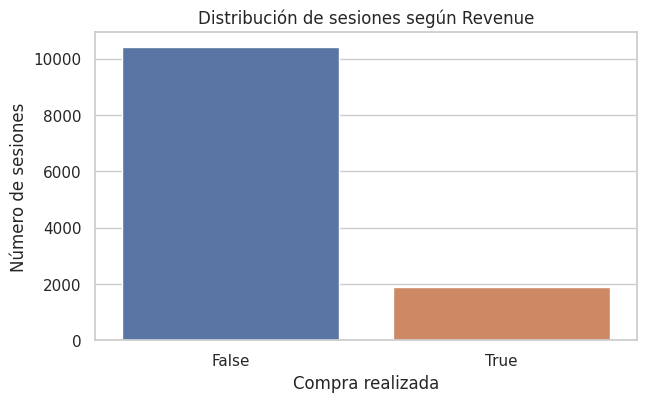

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Revenue', hue='Revenue', legend=False)
plt.title('Distribución de sesiones según Revenue')
plt.xlabel('Compra realizada')
plt.ylabel('Número de sesiones')
plt.show()


# Análisis univariado de las variables categóricas

In [ ]:
for v in variables_categoricas:
    print(f"\nFrecuencias de {v}:")
    print(df[v].value_counts())
    print("\nPorcentajes:")
    print(df[v].value_counts(normalize=True) * 100)



Frecuencias de Month:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

Porcentajes:
Month
May     27.283049
Nov     24.314680
Mar     15.466342
Dec     14.006488
Oct      4.452555
Sep      3.633414
Aug      3.511760
Jul      3.503650
June     2.335766
Feb      1.492295
Name: proportion, dtype: float64

Frecuencias de OperatingSystems:
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64

Porcentajes:
OperatingSystems
2    53.536091
1    20.965126
3    20.721817
4     3.876723
8     0.640714
6     0.154096
7     0.056772
5     0.048662
Name: proportion, dtype: float64

Frecuencias de Browser:
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64

Porcentajes:
Browser
2     64.566099
1

**Observaciones:**

- **`Month`.** Mayo y noviembre concentran poco más de la mitad de las sesiones (**51.60 %** en conjunto). Mayo tiene el mayor número de registros (**3,364**) y febrero tiene el menor (**184**) entre los meses presentes en el conjunto de datos.

- **`OperatingSystems` y `Browser`.** El código **2** es el más frecuente en cada variable: representa el **53.54 %** de las sesiones en `OperatingSystems` y el **64.57 %** en `Browser`. En esta última variable, el código **9** aparece en una sola sesión.

- **`Region`.** Los códigos **1** y **3** reúnen el **58.26 %** de las sesiones. La región con código **1** tiene casi el doble de registros que la región con código **3** (4,780 frente a 2,403).

- **`TrafficType`.** Los códigos **2, 1 y 3** concentran el **68.26 %** de las sesiones. Los códigos **12** y **17** tienen una sola sesión cada uno, por lo que cualquier tasa de compra calculada para esas categorías dependería de una sola observación.

- **`VisitorType`.** Predominan las sesiones de visitantes recurrentes (**85.57 %**), seguidas por las de visitantes nuevos (**13.74 %**) y las de la categoría `Other` (**0.69 %**).

- **`Weekend`.** El **76.74 %** de las sesiones ocurrió fuera del fin de semana y el **23.26 %** ocurrió en fin de semana.

- **`Revenue`.** La variable objetivo presenta un **desbalance de clases**: **10,422 sesiones (84.53 %)** terminaron sin compra y **1,908 (15.47 %)** terminaron en compra.

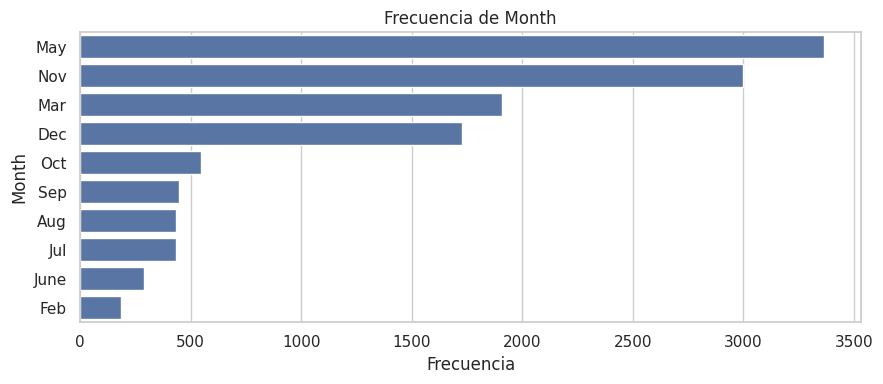

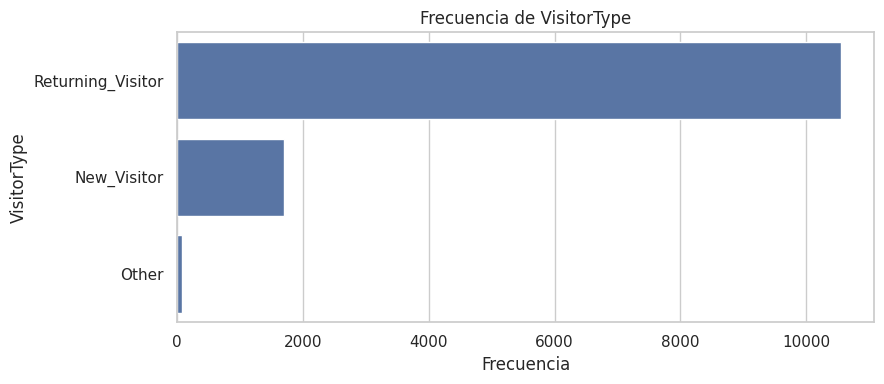

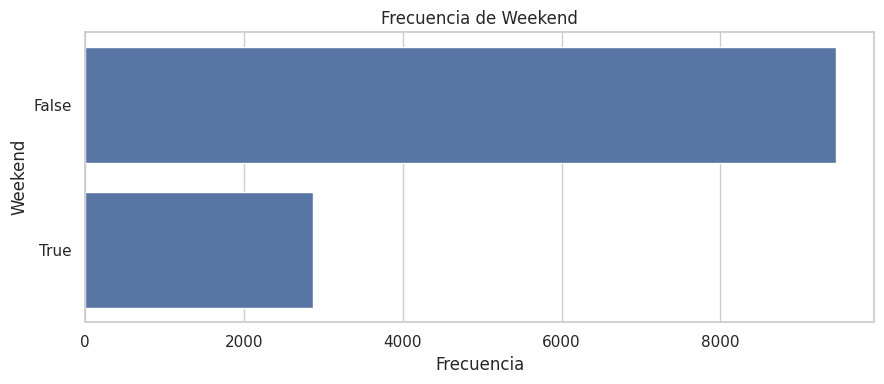

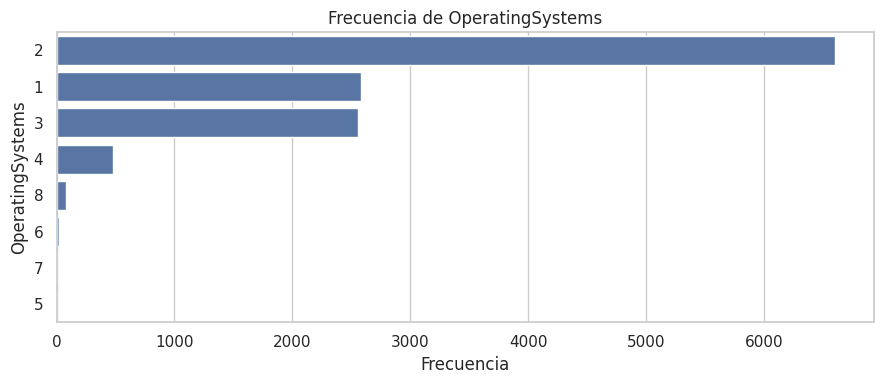

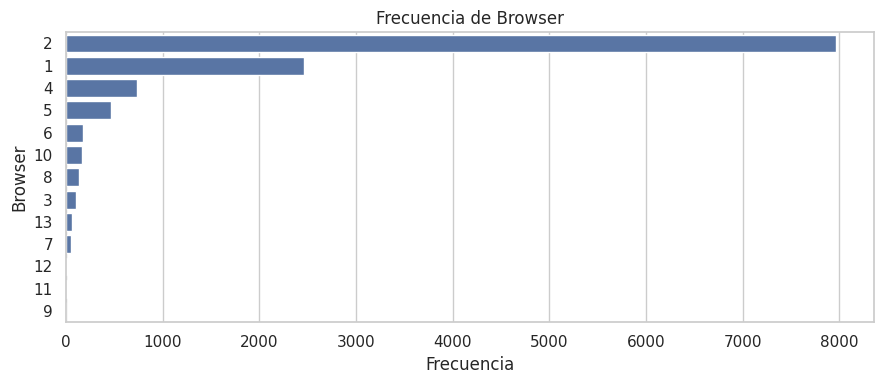

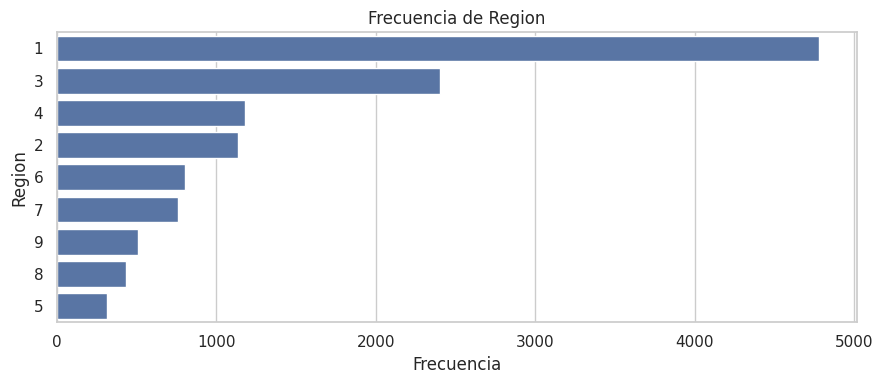

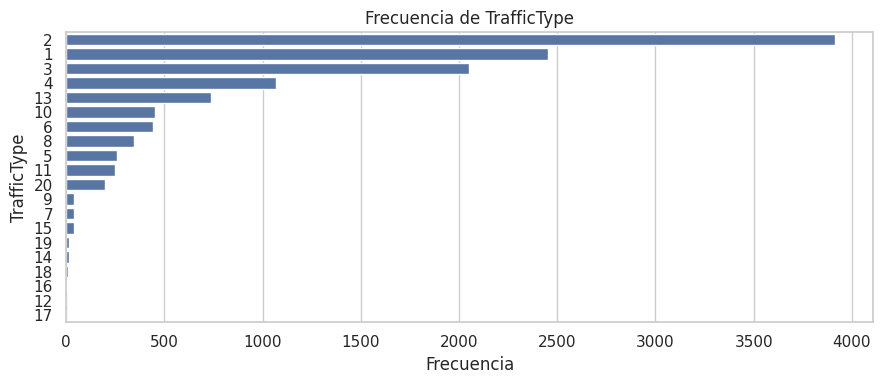

In [ ]:
for v in ['Month', 'VisitorType', 'Weekend',
          'OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    plt.figure(figsize=(9, 4))
    sns.countplot(data=df, y=v, order=df[v].value_counts().index)
    plt.title(f'Frecuencia de {v}')
    plt.xlabel('Frecuencia')
    plt.ylabel(v)
    plt.tight_layout()
    plt.show()


**Observaciones**

- **`Month`**. Mayo concentra la mayor proporción de sesiones (**27.28 %**), seguido de noviembre (**24.31 %**).
- **`VisitorType`**. Los visitantes recurrentes representan el **85.57 %** de las sesiones, mientras que los visitantes nuevos representan el **13.74 %**.
- **`Weekend`**. El **76.74 %** de las sesiones ocurrió entre  semana.
- **`OperatingSystems`**. El código **2** es el más frecuente, con el **53.54 %** de las sesiones.
- **`Browser`**. El código **2** concentra el **64.57 %** de las sesiones, seguido por el código **1**, con el **19.97 %**.
- **`Region`**. La región con código **1** concentra el **38.77 %** de las sesiones y la región con código **3**, el **19.49 %**.
- **`TrafficType`**. El código **2** es el más frecuente (**31.74 %**), seguido por los códigos **1** (**19.88 %**) y **3** (**16.64 %**).

## Histogramas de variables numéricas
Los histogramas permiten observar la forma de las distribuciones, concentraciones y posibles asimetrías.

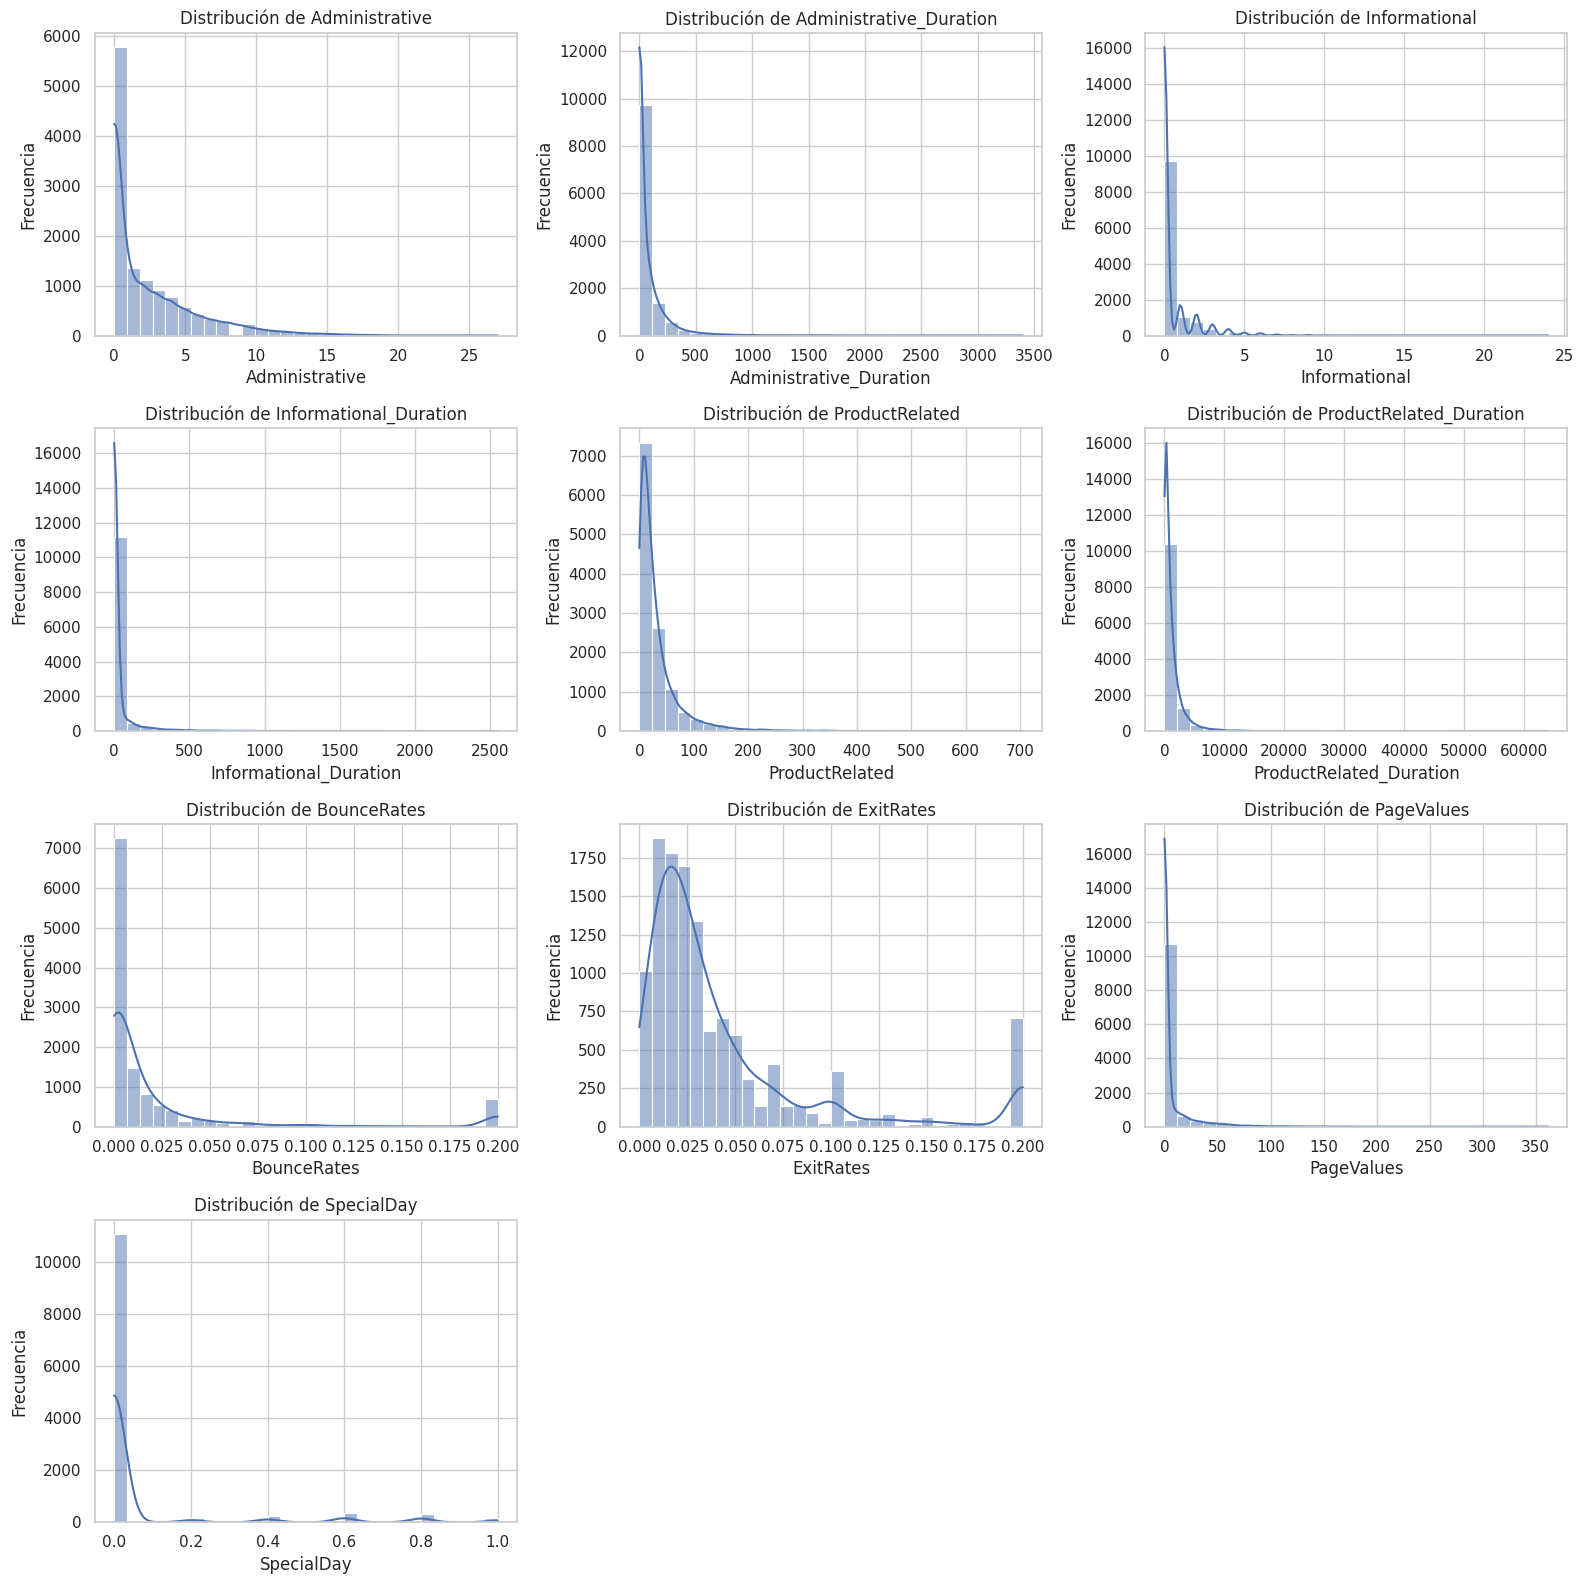

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.histplot(df[v], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


**Observaciones**

- `Administrative` y `Administrative_Duration`: La mayoría de las sesiones registró pocas páginas administrativas y poco tiempo en esa sección. La frecuencia disminuye a medida que aumentan el número de páginas y la duración.

- `Informational` e `Informational_Duration`: En ambos histogramas hay una concentración marcada en cero. Esto indica que gran parte de las sesiones no incluyó visitas a páginas informativas.

- `ProductRelated` y `ProductRelated_Duration`: Ambas distribuciones presentan **asimetría hacia la derecha**. La mayoría de las sesiones se concentra en conteos y duraciones bajos respecto al rango total. Hubo muchas sesiones con menos páginas y tiempos más cortos, y unas pocas con muchísimas páginas o duraciones muy largas.

- `BounceRates` y `ExitRates`: La tasa de rebote se concentra cerca de cero, mientras que la tasa de salida alcanza su mayor frecuencia en valores bajos por encima de cero. En ambas gráficas se observa una acumulación adicional cerca de **0.20 (20 %)**, en el extremo superior del rango observado.

- `PageValues`: Los valores se concentran en cero o cerca de cero. La cola hacia la derecha indica que solo una pequeña parte de las sesiones registró valores altos.

- `SpecialDay`: Predomina el valor **0**. Los valores positivos aparecen en grupos pequeños y separados, correspondientes a distintos niveles de cercanía a fechas especiales.

## Boxplots para detectar posibles valores atípicos
Los diagramas de caja permiten observar la mediana, los cuartiles, la dispersión y posibles observaciones alejadas. Un punto marcado como atípico debe investigarse; no se elimina automáticamente.

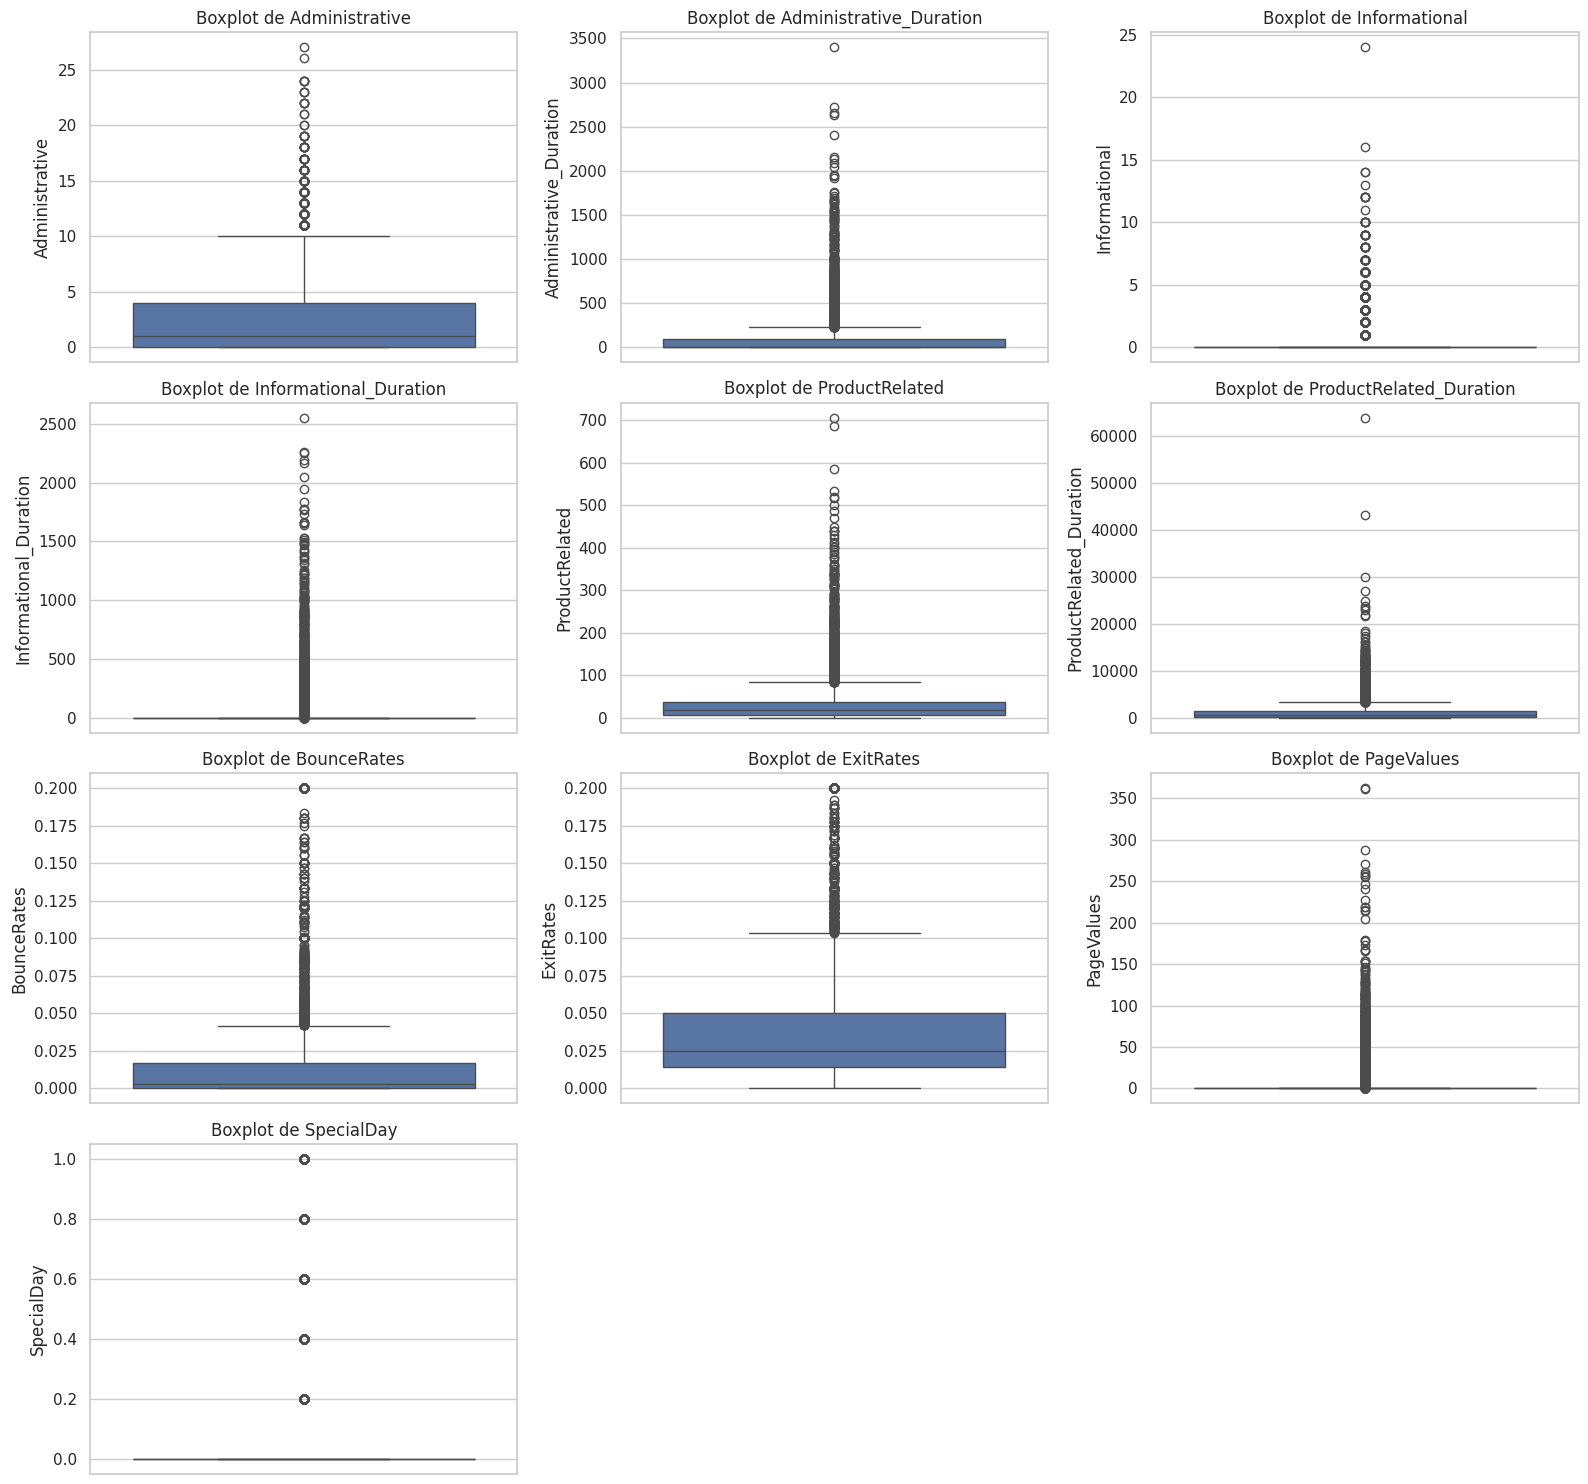

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
axes = axes.flatten()

for i, v in enumerate(variables_numericas):
    sns.boxplot(data=df, y=v, ax=axes[i])
    axes[i].set_title(f'Boxplot de {v}')

for j in range(len(variables_numericas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


**Observaciones**

- **`Administrative`** y **`Administrative_Duration`** presentan muchos puntos por encima del bigote superior.
- En **`ProductRelated`** y **`ProductRelated_Duration`**, se observan máximos de **705 páginas** y **63,973.52 segundos**, respectivamente.
- **`BounceRates`** y **`ExitRates`** presentan puntos por encima del bigote superior. En ambos casos, el máximo observado es de **0.20**.
- En **`Informational`**, **`Informational_Duration`**, **`PageValues`** y **`SpecialDay`**, el primer y el tercer cuartil son cero. Por eso la caja se reduce a una línea y la regla del rango intercuartílico señala los valores positivos como posibles atípicos.
- La validación de consistencia arrojó cero incidencias para las reglas revisadas. Aun así, los boxplots muestran valores atípicos respecto a la distribución de cada variable. Por ejemplo, en `SpecialDay` ambos cuartiles son cero, por lo que los valores positivos aparecen fuera del bigote aunque estén dentro del rango permitido. Los valores señalados se conservaron durante el análisis exploratorio.

## Diagramas	de	dispersión
Se exploran relaciones entre variables de navegación. El color distingue las sesiones que terminaron en compra de las que no.

Páginas de productos vs. duración de navegación

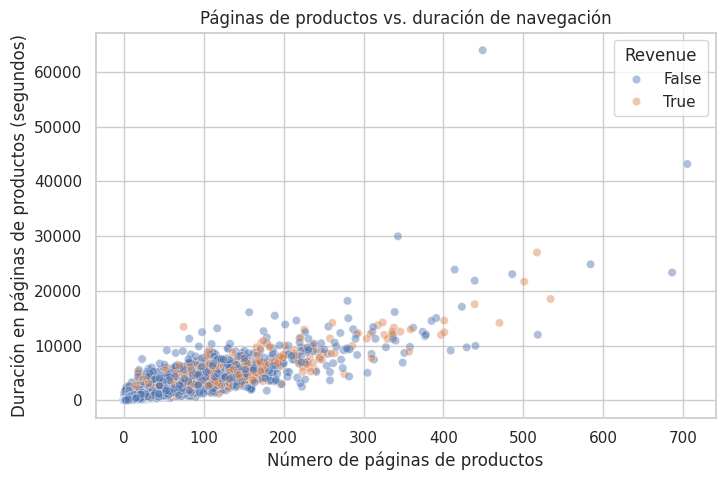

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='ProductRelated',
    y='ProductRelated_Duration',
    hue='Revenue',
    alpha=0.45
)
plt.title('Páginas de productos vs. duración de navegación')
plt.xlabel('Número de páginas de productos')
plt.ylabel('Duración en páginas de productos (segundos)')
plt.show()


**Observaciones**

- Se observa una **relación positiva** entre el número de páginas de productos visitadas y el tiempo registrado en ellas. Conforme aumenta el número de páginas, la duración tiende a aumentar y también se vuelve más variable.
- Las sesiones con y sin compra se superponen en la gráfica.

**Diagrama de	dispersión**

Tasa de rebote vs. tasa de salida

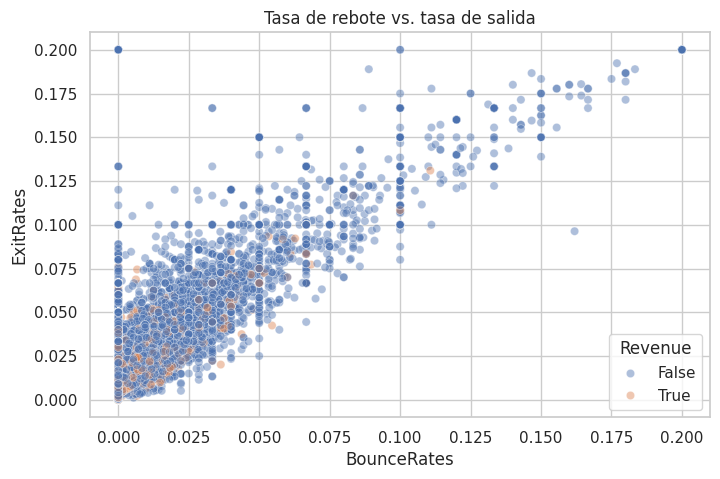

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='BounceRates',
    y='ExitRates',
    hue='Revenue',
    alpha=0.45
)
plt.title('Tasa de rebote vs. tasa de salida')
plt.xlabel('BounceRates')
plt.ylabel('ExitRates')
plt.show()


**Observaciones**

- Se observa una **tendencia ascendente** entre `BounceRates` y `ExitRates`. Las sesiones con mayor tasa de rebote tienden a presentar una mayor tasa de salida.
- Las sesiones con compra se concentran principalmente en la zona de tasas bajas, donde también aparecen muchas sesiones sin compra.

## Mapa de calor de correlaciones
La correlación de Pearson permite observar relaciones lineales entre las variables numéricas. Una correlación no demuestra causalidad.

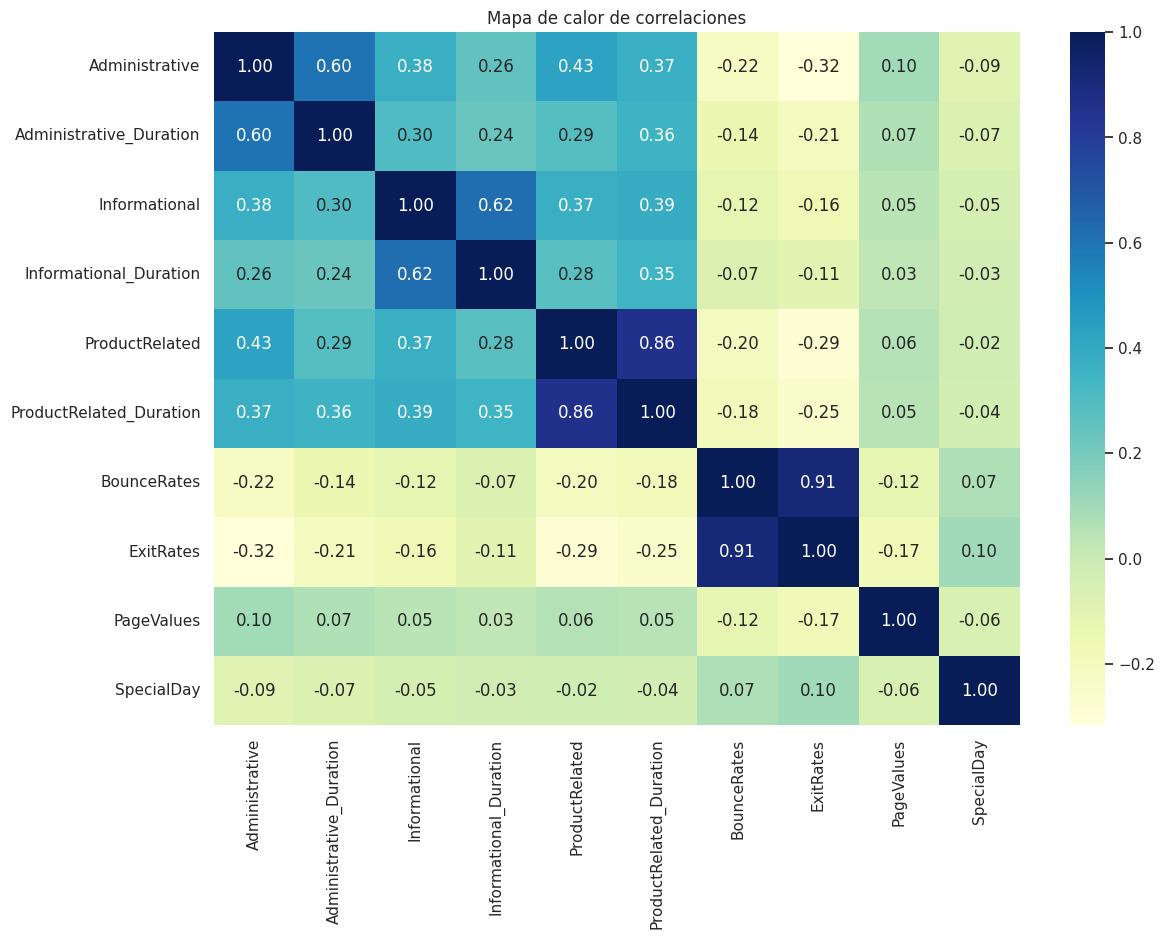

In [ ]:
matriz_correlacion = df[variables_numericas].corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)
plt.title('Mapa de calor de correlaciones')
plt.show()


**Observaciones**

- Tasa de rebote y tasa de salida: `BounceRates` y `ExitRates`, r = 0.91. Es la correlación más alta entre dos variables distintas. Las sesiones con una tasa de rebote más alta tienden a registrar también una tasa de salida más alta.

- Páginas de productos y tiempo de navegación: `ProductRelated` y `ProductRelated_Duration`, r = 0.86. Las sesiones en las que se consultaron más páginas de productos tendieron a registrar más tiempo en esa sección. También se observa esta tendencia en las páginas informativas **(r = 0.62)** y administrativas **(r = 0.60)**, aunque la relación es menos fuerte.

- Tasa de salida y páginas administrativas: `ExitRates` y `Administrative`, r = −0.32. Es la correlación negativa de mayor magnitud en el mapa. Las sesiones con una tasa de salida más alta tendieron a registrar menos páginas administrativas, aunque la relación es más débil que la observada entre las tasas de rebote y salida.

- Cercanía a fechas especiales: `SpecialDay`: Sus correlaciones con las demás variables numéricas van de −0.09 a 0.10. Como estos valores están cerca de cero, la correlación es débil.

## Comparación de variables categóricas con Revenue
Se utilizan tablas cruzadas normalizadas por fila para comparar el porcentaje de compras dentro de cada categoría.

In [ ]:
for v in ['Month', 'VisitorType', 'Weekend']:
    print(f"\nPorcentaje de Revenue según {v}:")
    tabla = pd.crosstab(df[v], df['Revenue'], normalize='index') * 100
    display(tabla.round(2))



Porcentaje de Revenue según Month:


Revenue,False,True
Month,,
Aug,82.45,17.55
Dec,87.49,12.51
Feb,98.37,1.63
Jul,84.72,15.28
June,89.93,10.07
Mar,89.93,10.07
May,89.15,10.85
Nov,74.65,25.35
Oct,79.05,20.95



Porcentaje de Revenue según VisitorType:


Revenue,False,True
VisitorType,,
New_Visitor,75.09,24.91
Other,81.18,18.82
Returning_Visitor,86.07,13.93



Porcentaje de Revenue según Weekend:


Revenue,False,True
Weekend,,
False,85.11,14.89
True,82.60,17.40


**Observaciones**

- **`VisitorType`**. El **24.91 %** de las sesiones de visitantes nuevos terminó en compra, frente al **13.93 %** de las sesiones de visitantes recurrentes.
- **`Month`**. Noviembre registró la mayor proporción de sesiones con compra (**25.35 %**). Mayo tuvo el mayor número de sesiones, con una proporción de compra del **10.85 %**.
- **`Weekend`**. El **17.40 %** de las sesiones de fin de semana terminó en compra, frente al **14.89 %** de las sesiones fuera del fin de semana.

## Revision PageValues antes de construir el clasificador
La descripción del dataset define PageValues como el valor promedio atribuido a las páginas visitadas antes de completar una transacción. Por eso debemos revisar su relación con Revenue y considerar si estaría disponible en el momento real en que se desea predecir la compra.

Si la variable contiene información que solo se conoce después de la compra, utilizarla podría provocar fuga de información (data leakage). No la eliminamos automáticamente: documentamos el hallazgo y compararemos su inclusión y exclusión al construir el modelo.

In [ ]:
print("PageValues por Revenue:")
display(
    df.groupby('Revenue')['PageValues']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(3)
)

print("Porcentaje de sesiones con PageValues mayor que cero:")
display(
    (pd.crosstab(df['Revenue'], df['PageValues'] > 0, normalize='index') * 100)
    .round(2)
)


PageValues por Revenue:


,count,mean,median,min,max
Revenue,,,,,
False,10422,1.976,0.000,0.0,246.759
True,1908,27.265,16.758,0.0,361.764


Porcentaje de sesiones con PageValues mayor que cero:


PageValues,False,True
Revenue,,
False,88.56,11.44
True,19.39,80.61


**Observaciones**

- **`PageValues` fue mayor que cero en el 80.61 % de las sesiones con compra** y en el **11.44 % de las sesiones sin compra**.
- La mediana de `PageValues` fue de **16.76** en las sesiones con compra y de **0** en las sesiones sin compra.